# 哈密顿量

## 0.Pauli算符期望值

In [26]:
import numpy as np
from pyqpanda3.hamiltonian import Hamiltonian, PauliOperator
from pyqpanda3.core import expval_hamiltonian, expval_pauli_operator
from pyqpanda3.core import QProg, H, CNOT, RY, measure, CPUQVM

构造量子态:

$$
|\psi\rangle = |+\rangle = \frac{1}{\sqrt{2}}\left(|0\rangle + |1\rangle \right)
$$

Pauli矩阵 $X$ 的期望值为：

**方法一**：
$$
\langle X \rangle = \langle +|X|+\rangle = \frac{\langle 0| + \langle 1|}{\sqrt{2}} X \frac{|0\rangle + |1\rangle}{\sqrt{2}} = \frac{\langle 0| + \langle 1|}{\sqrt{2}}\frac{|1\rangle + |0\rangle}{\sqrt{2}} = 1
$$

**方法二**：
$$
\langle X \rangle = \lambda_{+}P_{+} + \lambda_{-}P_{-} = 1 \times 1 + (-1) \times 0 = 1
$$

In [27]:
prog1 = QProg()
prog1 << H(0)

┌─┐ 
q_0:  |0>─┤H├ 
          └─┘ 
 c :   / ════

**理论计算**

In [28]:
pauli_op = PauliOperator('X')
pauli_op_expectation = expval_pauli_operator(prog1, pauli_op)
print(f"Theoretical expectation value of X is: {pauli_op_expectation:.6f}")

Theoretical expectation value of X is: 1.000000


**模拟计算**

先进行换基操作，在测量之前添加 $H$ 门

In [29]:
prog1 << H(0) << measure(0, 0)

┌─┐ ┌─┐  ┌─┐ 
q_0:  |0>─┤H├ ┤H├ ─┤M├ 
          └─┘ └─┘  └╥┘ 
 c :   / ═══════════╩═
                     0

In [30]:
qvm = CPUQVM()
shots = 1000
qvm.run(prog1, shots)
result = qvm.result().get_counts()

simulated_expectation = result.get('0', 0) / shots - result.get('1', 0) / shots
print(f"Simulated expectation value of X is: {simulated_expectation:.6f}")

Simulated expectation value of X is: 1.000000


## 1.模拟器理论计算期望值

$$
H = 0.5 I + 0.7 Z_0 - 0.2 Z_1 + 0.6 X_0X_1
$$

In [31]:
# 字典：空字符串表示恒等项，未出现的比特默认作用 I
ham = Hamiltonian({"": 0.5, "Z0": 0.7, "Z1": -0.2, "X0 X1": 0.6})

In [32]:
# 构建态制备线路
prog = QProg()
prog << RY(0, np.pi/3) << CNOT(0, 1)

┌──┐        
q_0:  |0>─┤RY├ ───*── 
          └──┘ ┌──┴─┐ 
q_1:  |0>───── ┤CNOT├ 
               └────┘ 
 c :   / ════════════

In [33]:
# 计算期望值
exp_val = expval_hamiltonian(prog, ham)
print(f"Expectation value: {exp_val:.6f}")

Expectation value: 1.269615


## 2. 噪声模拟器计算期望值

In [34]:
from pyqpanda3.core import NoiseModel, depolarizing_error, GateType

In [35]:
error = depolarizing_error(0.1)

model = NoiseModel()
model.add_quantum_error(error, GateType.CNOT, [0, 1])

In [41]:
prog = QProg()
prog << RY(0, np.pi/3) << CNOT(0, 1)

┌──┐        
q_0:  |0>─┤RY├ ───*── 
          └──┘ ┌──┴─┐ 
q_1:  |0>───── ┤CNOT├ 
               └────┘ 
 c :   / ════════════

**注意**：使用含噪声模拟计算哈密顿量期望值时，需要添加 `measure`

In [42]:
prog << measure(0, 0) << measure(1, 1)

┌──┐         ┌─┐     
q_0:  |0>─┤RY├ ───*── ─┤M├──── 
          └──┘ ┌──┴─┐  └╥┘ ┌─┐ 
q_1:  |0>───── ┤CNOT├ ──╫──┤M├ 
               └────┘   ║  └╥┘ 
 c :   / ═══════════════╩═══╩═
                         0   1

**注意**：当 shots=1 时，函数使用态矢量模拟计算精确期望值。当 shots > 1 时，它使用指定次数的测量进行基于采样的估计。

In [43]:
exp_val = expval_hamiltonian(prog, ham, shots=1000, model=model)
print(f"Expectation value: {exp_val:.6f}")

Expectation value: 1.159200


## 3. 真机计算哈密顿量期望值

In [46]:
import os
from pyqpanda3.hamiltonian import Hamiltonian
from pyqpanda3.qcloud import QCloudOptions, QCloudService, QCloudJob

In [47]:
prog = QProg()
prog << RY(0, np.pi/3) << CNOT(0, 1)

┌──┐        
q_0:  |0>─┤RY├ ───*── 
          └──┘ ┌──┴─┐ 
q_1:  |0>───── ┤CNOT├ 
               └────┘ 
 c :   / ════════════

In [48]:
APIKEY = os.getenv('APIKEY')
service = QCloudService(APIKEY)

In [49]:
backend = service.backend("WK_C180")
exp_val = backend.expval_hamiltonian(prog, ham, QCloudOptions())
print(f"Expectation value: {exp_val:.6f}")

Expectation value: 1.471787


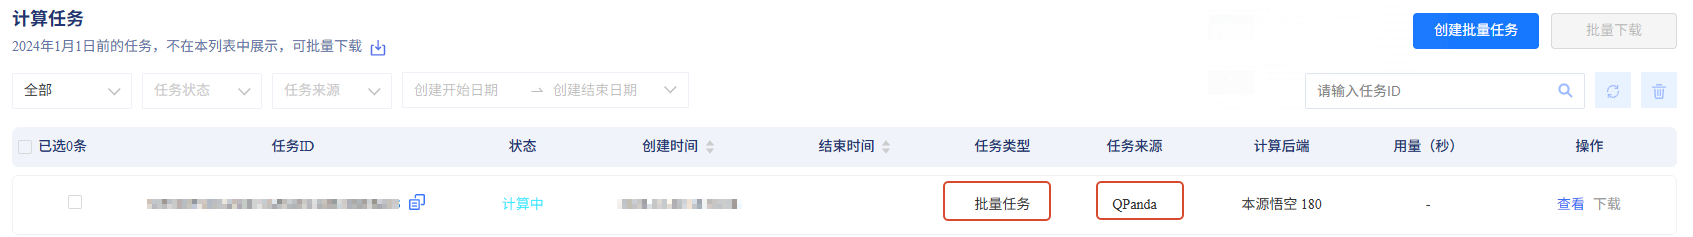

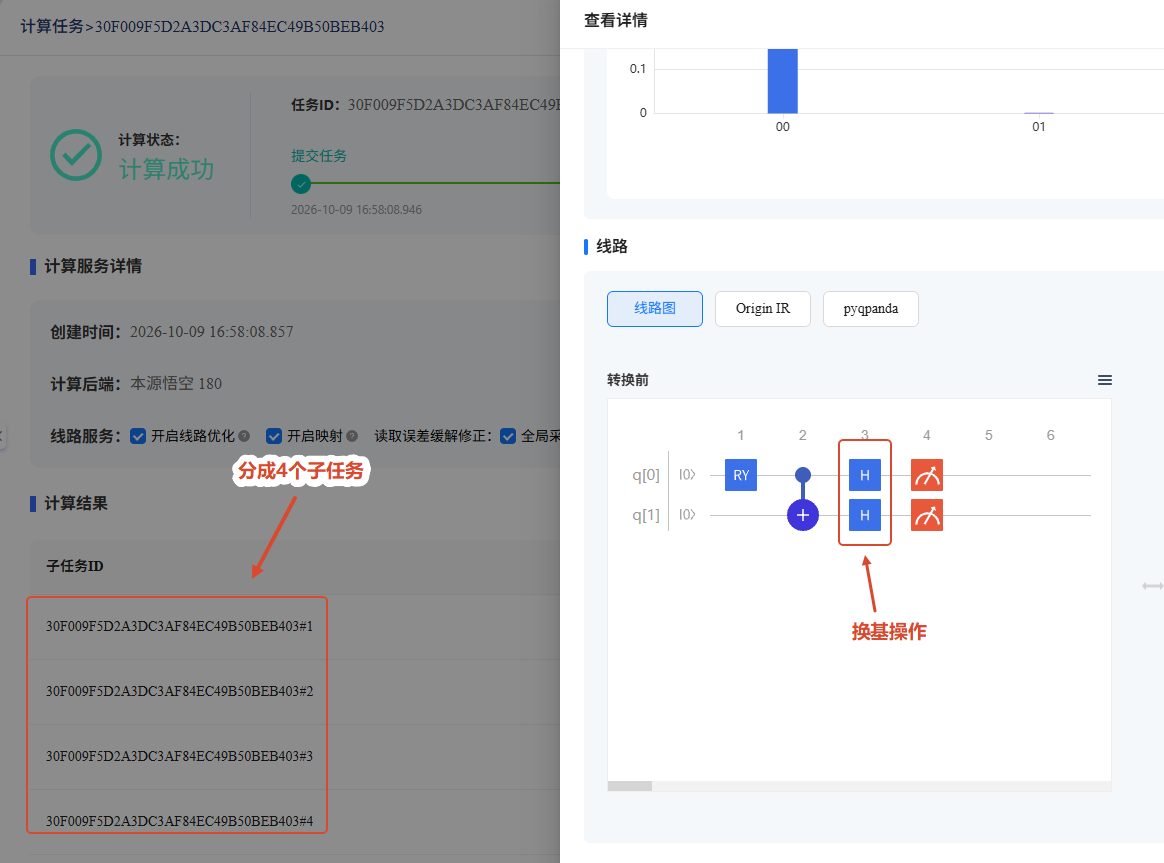

# 变分量子线路

In [40]:
import numpy as np
from scipy.optimize import minimize
from pyqpanda3.core import X, RY, CNOT, QProg
from pyqpanda3.core import expval_hamiltonian
from pyqpanda3.vqcircuit import VQCircuit
from pyqpanda3.hamiltonian import Hamiltonian

**构建哈密顿量**

$$
\begin{align}
H &= -1.052373 I_0 \otimes I_1 + 0.397937 Z_0 \otimes I_1 - 0.397937 I_0 \otimes Z_1 - 0.011280 Z_0 \otimes Z_1 + 0.180931 X_0 \otimes X_1 \\
&= -1.052373 \begin{bmatrix} 1&0&0&0\\ 0&1&0&0 \\ 0&0&1&0 \\ 0&0&0&1 \\ \end{bmatrix} + 0.397937 \begin{bmatrix} 1&0&0&0\\ 0&1&0&0 \\ 0&0&-1&0 \\ 0&0&0&-1 \\ \end{bmatrix} - 0.397937 \begin{bmatrix} 1&0&0&0\\ 0&-1&0&0 \\ 0&0&1&0 \\ 0&0&0&-1 \\ \end{bmatrix} - 0.011280 \begin{bmatrix} 1&0&0&0\\ 0&-1&0&0 \\ 0&0&-1&0 \\ 0&0&0&1 \\ \end{bmatrix} + 0.180931 \begin{bmatrix} 0&0&0&1\\ 0&0&1&0 \\ 0&1&0&0 \\ 1&0&0&0 \\ \end{bmatrix} \\
&= \begin{bmatrix} -1.063653&0&0&0.180931\\ 0&-0.245219&0.180931&0 \\ 0&0.180931&-1.836967&0 \\ 0.180931&0&0&-1.063653 \\ \end{bmatrix}
\end{align}
$$

In [41]:
def step1_define_hamiltonian() -> Hamiltonian:
    # 字典构造法
    hamiltonian = Hamiltonian(
        {
            "I0 I1": -1.052373,
            "Z0": 0.397937,
            "Z1": -0.397937,
            "Z0 Z1": -0.011280,
            "X0 X1": 0.180931
        }
    )

    # 列表构造法
    hamiltonian = Hamiltonian(
        ["I0 I1", "Z0", "Z1", "Z0 Z1", "X0 X1"],
        [-1.052373, 0.397937, -0.397937, -0.011280, 0.180931]
    )
    return hamiltonian

**构建量子态**

$$
|00\rangle \xrightarrow{X_0} |10\rangle \xrightarrow{RY(1, \theta)}  \cos \frac{\theta}{2} |10\rangle + \sin \frac{\theta}{2} |11\rangle \xrightarrow{CNOT(1, 0)} \cos \frac{\theta}{2} |10\rangle + \sin \frac{\theta}{2} |01\rangle
$$

$$
|\psi(\theta)\rangle = \cos \frac{\theta}{2} |10\rangle + \sin \frac{\theta}{2} |01\rangle
$$

In [42]:
def step2_build_ansatz(params) -> QProg:
    ansatz = QProg()
    ansatz << X(0) << RY(1, params[0]) << CNOT(1, 0)
    return ansatz

指定参数 $\theta$ 的值，计算哈密顿量期望值

In [43]:
def step3_get_expectation(params):
    hamiltonian = step1_define_hamiltonian()
    ansatz = step2_build_ansatz(params)
    expectation = expval_hamiltonian(ansatz, hamiltonian)
    return expectation

理论值

$$
\begin{align}
\langle H \rangle &= \langle H(\theta) \rangle \\
&= \langle \psi(\theta)| H | \psi(\theta)\rangle \\
&= \left(\cos \frac{\theta}{2} \langle 10| + \sin \frac{\theta}{2} \langle01|\right) H \left(\cos \frac{\theta}{2} |10\rangle + \sin \frac{\theta}{2} |01\rangle\right) \\
&= \begin{bmatrix}0&\sin\frac{\theta}{2}&\cos\frac{\theta}{2}&0\end{bmatrix} \begin{bmatrix} -1.063653&0&0&0.180931\\ 0&-0.245219&0.180931&0 \\ 0&0.180931&-1.836967&0 \\ 0.180931&0&0&-1.063653 \\ \end{bmatrix} \begin{bmatrix}0\\ \sin\frac{\theta}{2}\\ \cos\frac{\theta}{2}\\0\end{bmatrix} \\
&= \begin{bmatrix}0&\sin\frac{\theta}{2}&\cos\frac{\theta}{2}&0\end{bmatrix} \begin{bmatrix}0\\ -0.245219\sin\frac{\theta}{2}+0.180931\cos\frac{\theta}{2} \\ 0.180931\sin\frac{\theta}{2}-1.836967\cos\frac{\theta}{2}\\0\end{bmatrix} \\
&= -0.245219 \sin^2\frac{\theta}{2} + 0.180931\sin\theta -1.836967\cos^2\frac{\theta}{2} \\
&= 0.180931\sin\theta-0.795874\cos\theta - 1.041093 \\
&= 0.816181\sin(\theta-\theta_0) - 1.041093
\end{align}
$$

其中，$\theta_0 = \tan^{-1}(0.795874/0.180931) = 1.347259$.

显然，当 
$$
\theta-\theta_0 = -\frac{\pi}{2} + 2n\pi, n\in \mathbb{N}
$$

即
$$
\theta = -0.223536 + 2n\pi, n\in \mathbb{N}
$$

$\langle H(\theta)\rangle$ 取最小值 $-0.816181-1.041093=-1.857274$

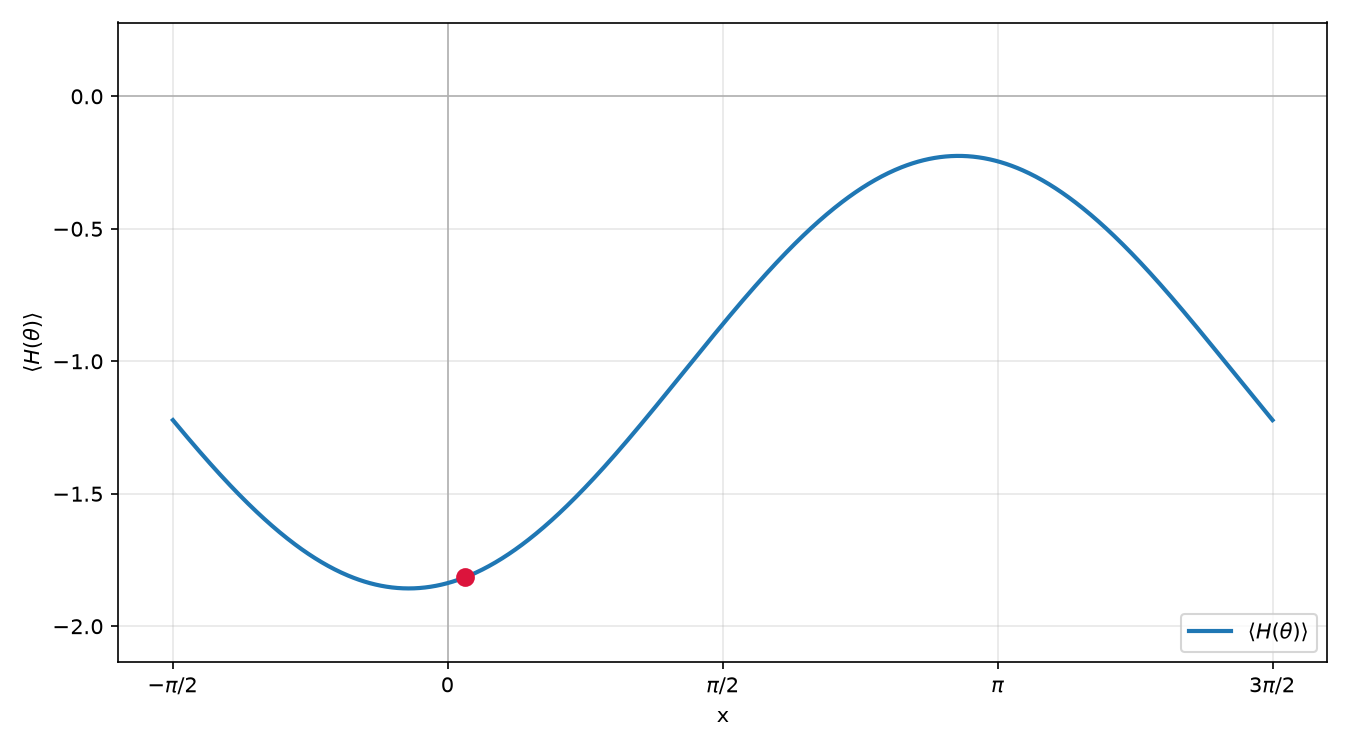

In [45]:
initial_guess = np.array([0.1])
result = minimize(
    step3_get_expectation,
    initial_guess,
    method='COBYLA',
    options={'maxiter': 200}
)
print(result)
print(f"Minimum energy: {result.fun:.6f}")
print(f"Optimal parameters: {result.x}")

 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: -1.857274015293491
       x: [-2.235e-01]
    nfev: 24
   maxcv: 0.0
Minimum energy: -1.857274
Optimal parameters: [-0.2235]


# 含噪声模拟

## 1. 门噪声

In [1]:
from pyqpanda3.core import depolarizing_error, GateType, NoiseModel

# Add error to a specific gate type on specific qubits
error = depolarizing_error(0.01)
noise = NoiseModel()

### 1.1 特定比特上的特定门

In [2]:
noise.add_quantum_error(error, GateType.CNOT, [0, 1])

### 1.2 特定比特上的多个门

In [3]:
noise.add_quantum_error(error, [GateType.H, GateType.T], [0])

### 1.3 所有比特上的特定门

In [4]:
noise.add_all_qubit_quantum_error(error, GateType.CNOT)

### 1.4 所有比特上的多个门

In [5]:
noise.add_all_qubit_quantum_error(error, [GateType.H, GateType.CNOT])

## 2. 测量噪声

### 2.1 特定比特的测量噪声

In [ ]:
noise.add_read_out_error([[0.95, 0.05], [0.05, 0.95]], 0)

### 2.2 所有比特的测量噪声

In [ ]:
noise.add_all_qubit_read_out_error([[0.95, 0.05], [0.05, 0.95]])

## 示例

In [8]:
from pyqpanda3.core import H, CNOT, QProg, measure, CPUQVM, GateType
from pyqpanda3.core import depolarizing_error, NoiseModel

In [9]:
prog = QProg()
prog << H(0) << CNOT(0, 1)
prog << measure([0, 1], [0, 1])

┌─┐         ┌─┐     
q_0:  |0>─┤H├ ───*── ─┤M├──── 
          └─┘ ┌──┴─┐  └╥┘ ┌─┐ 
q_1:  |0>──── ┤CNOT├ ──╫──┤M├ 
              └────┘   ║  └╥┘ 
 c :   / ══════════════╩═══╩═
                        0   1

In [10]:
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(
    depolarizing_error(0.01), GateType.CNOT
)

In [11]:
machine = CPUQVM()
machine.run(prog, shots=100000, model=noise_model)

In [12]:
counts = machine.result().get_counts()
print(counts)
total = sum(counts.values())
p00 = counts.get('00', 0) / total
p11 = counts.get('11', 0) / total
print(f"P(00)={p00:.4f}  P(11)={p11:.4f}")
print(f"Bell fidelity (with 100k shots): {p00 + p11:.4f}")

{'01': 483, '10': 477, '00': 49470, '11': 49570}
P(00)=0.4947  P(11)=0.4957
Bell fidelity (with 100k shots): 0.9904


# 量子加法器

In [ ]:
from pyqpanda3.core import X, CNOT, QProg, measure, CPUQVM, draw_qprog

In [ ]:
def adder_2bit(a: int, b: int, s: int, c: int) -> QProg:
    prog = QProg()
    prog << X(c).control([a, b])
    prog << X(s).control(a)
    prog << X(s).control(b)
    return prog

In [ ]:
def adder_3bit(ai: int, bi: int, ci: int, s: int, c: int) -> QProg:
    prog = QProg()
    prog << X(s).control(ai) << X(s).control(bi) << X(s).control(ci)
    prog << X(bi).control(ai) << X(ci).control(ai) << X(c).control([bi, ci])
    prog << X(c).control(ai) << X(ci).control(ai) << X(bi).control(ai)
    return prog

In [ ]:
def adder_circuit(a: int, b: int) -> QProg:
    n = max(a.bit_length(), b.bit_length())  # 获取二进制数的位数
    Qa, Qb, Qs, Qc = list(range(n)), list(range(n, 2*n)), list(range(2*n, 3*n)), list(range(3*n, 4*n))

    prog = QProg(4 * n)  # 共用到4n个量子比特
    for i in range(n):
        a_i = (a >> i) & 1  # 获取a的第i位
        b_i = (b >> i) & 1  # 获取b的第i位
        if a_i:
            prog << X(Qa[i])  # a_i所在的量子比特索引
        if b_i:
            prog << X(Qb[i])  # b_i所在的量子比特索引

    prog << adder_2bit(Qa[0], Qb[0], Qs[0], Qc[0])
    for i in range(1, n):
        prog << adder_3bit(Qa[i], Qb[i], Qc[i-1], Qs[i], Qc[i])

    for i in range(n):
        prog << measure(Qs[i], i)
    prog << measure(Qc[-1], n)

    return prog

In [ ]:
a, b = 230, 241
prog = adder_circuit(a, b)

In [ ]:
qvm = CPUQVM()
qvm.run(prog, 100)
result = qvm.result().get_counts()
print(result)

for state, cnt in result.items():
	print(f"{a} + {b} 的计算结果为：", int(state, base=2))

# Grover搜索算法

In [ ]:
import os
from math import ceil, pi, sqrt, floor
from typing import List
from pyqpanda3.core import X, H, Z, measure, QProg, CPUQVM
from pyqpanda3.qcloud import QCloudOptions, QCloudService, QCloudJob

In [ ]:
def init_state(qubits: List[int]) -> QProg:
    prog = QProg()
    for q in qubits:
        prog << H(q)
    return prog

In [ ]:
def build_oracle(qubits: List[int], dst: str) -> QProg:
    prog = QProg()
    n_qubits = len(qubits)
    for idx in range(n_qubits):
        if dst[idx] == '0':
            prog << X(qubits[n_qubits - 1 - idx])
    
    prog << Z(qubits[0]).control(qubits[1:])

    for idx in range(n_qubits):
        if dst[idx] == '0':
            prog << X(qubits[n_qubits - 1 - idx])
    return prog

In [ ]:
def build_diffusion(qubits: List[int]) -> QProg:
    prog = QProg()
    for q in qubits:
        prog << H(q) << X(q)
    
    prog << Z(qubits[0]).control(qubits[1:])

    for q in qubits:
        prog << X(q) << H(q)
    return prog

In [ ]:
n_qubits = 3
working_qubits = [0, 1, 2]
dst = '010'

prog = QProg()
prog << init_state(working_qubits)

iterations = pi/4*sqrt(2**n_qubits)
iterations = floor(iterations)

oracle = build_oracle(working_qubits, dst)
diffusion = build_diffusion(working_qubits)

for i in range(iterations):
	prog << oracle
	prog << diffusion

for q in working_qubits:
	prog << measure(q, q)

In [ ]:
APIKEY = os.getenv('APIKEY')
service = QCloudService(APIKEY)

# 查看可用计算后端
backends = service.backends()
print(backends)

# WK_C180是真机，选择使用这个后端
backend = service.backend('WK_C180')
options = QCloudOptions()
job = backend.run(prog, 10000, options)
# 查询任务结果，计算时间与任务队列中任务数量有关
result = job.result().get_probs()
print(result)

# AI工具